In [3]:
import pandas as pd
import plotly.express as px

df_limpo = pd.read_json("../dados/tratados/dados_inct_limpo.json")
NIVEL = 5.3

df_limpo.shape

(6674, 9)

# Análise exploratória dos dados do INCT SiMAI

Usamos o JSON já limpo (`dados/tratados/dados_inct_limpo.json`), com 6.674 linhas (71 níveis do Guaíba × 94 bairros). Todos os valores são **estimativas de uma simulação**, não previsões nem contagens oficiais.

In [5]:
import plotly.express as px

pop_nivel = df_limpo.groupby("nivel_m")["affected_population"].sum().reset_index()

fig = px.line(pop_nivel, x="nivel_m", y="affected_population",
              title="População afetada (estimativa) por nível do Guaíba",
              labels={"nivel_m": "Nível do Guaíba (m)",
                      "affected_population": "Pessoas afetadas (estimativa)"})
fig.add_vline(x=5.35, line_dash="dash", annotation_text="5,35 m (pico de 2024)")
fig.update_yaxes(rangemode="tozero")
fig.show()

### Gráfico 1: população afetada por nível do Guaíba

A população afetada estimada cresce de forma contínua com o nível: cerca de 35 mil pessoas em 3,0 m, 140 mil em 5,35 m (nível do pico de maio de 2024) e 275 mil em 10,0 m. Não há saltos bruscos após a limpeza dos dados. Já há população afetada em 3,0 m, o que é coerente com bairros como o Arquipélago, que tem quase todos os prédios afetados desde os níveis mais baixos.

In [6]:
top10 = (df_limpo[df_limpo["nivel_m"] == NIVEL]
         .sort_values("percentage", ascending=False)
         .head(10))

fig = px.bar(top10, x="percentage", y="bairro", orientation="h",
             title=f"10 bairros com maior % de prédios afetados (estimativa, {NIVEL} m)",
             labels={"percentage": "% de prédios afetados", "bairro": "Bairro"})
fig.update_yaxes(autorange="reversed")
fig.show()

### Gráfico 2: bairros com maior percentual de prédios afetados (5,3 m)

Com o Guaíba em 5,3 m, a simulação estima que seis bairros (Navegantes, Anchieta, Arquipélago, Praia de Belas, Humaitá e Farrapos) tenham todos os prédios afetados, e que outros quatro tenham entre 60% e 91%. Como vários bairros empatam em 100%, a ordem entre eles não indica diferença de impacto. O percentual é um número inteiro arredondado.

In [7]:
top10_pop = (df_limpo[df_limpo["nivel_m"] == NIVEL]
             .sort_values("affected_population", ascending=False)
             .head(10))

fig = px.bar(top10_pop, x="affected_population", y="bairro", orientation="h",
             title=f"10 bairros com mais pessoas afetadas (estimativa, {NIVEL} m)",
             labels={"affected_population": "Pessoas afetadas (estimativa)", "bairro": "Bairro"})
fig.update_yaxes(autorange="reversed")
fig.show()

### Gráfico 3: bairros com mais pessoas afetadas (5,3 m)

Os bairros com mais pessoas afetadas (Sarandi, Farrapos, Menino Deus e Humaitá, entre 12 mil e 24 mil) não coincidem totalmente com os de maior percentual de prédios afetados: Navegantes, Anchieta e Praia de Belas têm 100% dos prédios afetados, mas menos moradores. Por isso a proporção de prédios afetados e o número de pessoas afetadas precisam ser lidos juntos. A população afetada é calculada como população × % de prédios afetados, o que assume pessoas distribuídas igualmente entre os prédios do bairro.

In [8]:
bairros_nivel = (df_limpo[df_limpo["affected_buildings"] > 0]
                 .groupby("nivel_m")["bairro"].nunique().reset_index(name="n_bairros"))

fig = px.line(bairros_nivel, x="nivel_m", y="n_bairros",
              title="Bairros com algum prédio afetado (estimativa) por nível do Guaíba",
              labels={"nivel_m": "Nível do Guaíba (m)", "n_bairros": "Nº de bairros (de 94)"})
fig.add_vline(x=5.35, line_dash="dash", annotation_text="5,35 m (pico de 2024)")
fig.update_yaxes(rangemode="tozero")
fig.show()

### Gráfico 4: bairros com algum prédio afetado por nível

Em 3,0 m, 24 dos 94 bairros já têm algum prédio afetado; em 5,3 m, 36; e em 10,0 m, 54. A curva sobe mais rápido entre 3,0 e 3,4 m e depois cresce de forma gradual, em degraus, chegando a pouco mais da metade dos bairros no nível máximo. Ou seja, mesmo com o rio a 10 m, cerca de 40 bairros não têm prédios afetados nesta simulação.

(128, 2)
0       HIGIENÓPOLIS
1      VILA IPIRANGA
2    PARQUE SANTA FÉ
3      COSTA E SILVA
4        RUBEM BERTA
Name: nome, dtype: str


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

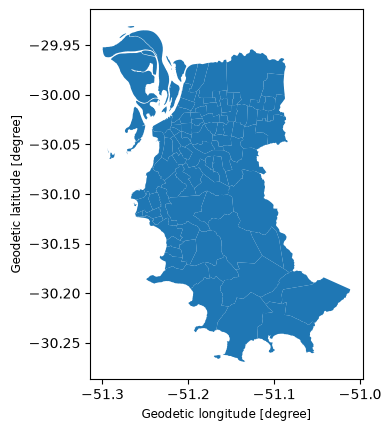

In [1]:
import geopandas as gpd

bairros = gpd.read_file("../dados/originais/bairros/bairros_poa.geojson")
print(bairros.shape)           # 128 linhas
print(bairros["nome"].head())  # os primeiros nomes
bairros.plot()                 # desenha o mapa

### Gráfico 5: limites dos bairros da Prefeitura

Os limites dos bairros da Prefeitura (128 polígonos, 94 bairros distintos, pois alguns bairros têm mais de uma parte) foram carregados com sucesso. Os nomes vêm em maiúsculas e precisam ser padronizados para casar com os do JSON do INCT.

In [6]:
import unicodedata
import geopandas as gpd

def normalizar(nome):
    nome = unicodedata.normalize("NFKD", str(nome))
    nome = "".join(c for c in nome if not unicodedata.combining(c))  # tira acentos
    nome = nome.replace("'", " ").replace("’", " ").replace("-", " ")
    return " ".join(nome.upper().split())                            # maiúsculo, sem espaços extras

bairros = gpd.read_file("../dados/originais/bairros/bairros_poa.geojson")
bairros["chave"] = bairros["nome"].apply(normalizar)
df_limpo["chave"] = df_limpo["bairro"].apply(normalizar)

chaves_inct = set(df_limpo["chave"])
chaves_pref = set(bairros["chave"])

print("Bairros no INCT:", len(chaves_inct))
print("Bairros na Prefeitura:", len(chaves_pref))
print("Casam:", len(chaves_inct & chaves_pref))

print("\nSó no INCT (sem par na Prefeitura):")
for n in sorted(chaves_inct - chaves_pref):
    print("  ", n)

print("\nSó na Prefeitura (sem par no INCT):")
for n in sorted(chaves_pref - chaves_inct):
    print("  ", n)

Bairros no INCT: 94
Bairros na Prefeitura: 94
Casam: 91

Só no INCT (sem par na Prefeitura):
   CORONEL APARICIO BORGES
   MONT SERRAT
   PASSO D AREIA

Só na Prefeitura (sem par no INCT):
   CEL. APARICIO BORGES
   MONTSERRAT
   PASSO DA AREIA


In [7]:
ajustes = {
    "CEL. APARICIO BORGES": "CORONEL APARICIO BORGES",
    "MONTSERRAT": "MONT SERRAT",
    "PASSO DA AREIA": "PASSO D AREIA",
}
bairros["chave"] = bairros["chave"].replace(ajustes)

chaves_pref = set(bairros["chave"])
print("Casam agora:", len(chaves_inct & chaves_pref), "de 94")
print("Sobraram só no INCT:", chaves_inct - chaves_pref)
print("Sobraram só na Prefeitura:", chaves_pref - chaves_inct)

Casam agora: 94 de 94
Sobraram só no INCT: set()
Sobraram só na Prefeitura: set()


In [8]:
bairros_94 = bairros.dissolve(by="chave", as_index=False)[["chave", "geometry"]]
print(bairros_94.shape)   # deve dar (94, 2)

(94, 2)


0 bairros sem valor


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

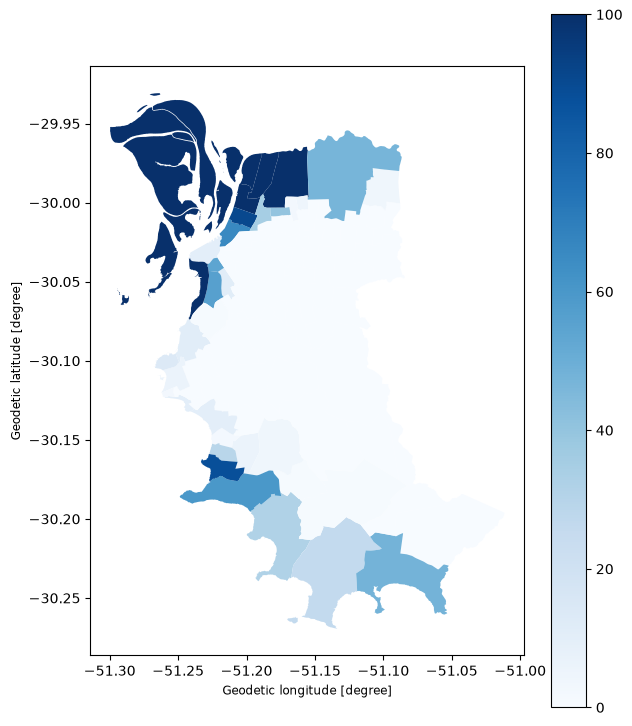

In [9]:
dados_nivel = df_limpo[df_limpo["nivel_m"] == NIVEL][["chave", "percentage"]]
mapa = bairros_94.merge(dados_nivel, on="chave", how="left")

print(mapa["percentage"].isna().sum(), "bairros sem valor")   # deve dar 0
mapa.plot(column="percentage", cmap="Blues", legend=True, figsize=(7, 9))

### Gráfico 6: mapa dos bairros por % de prédios afetados (5,3 m)